# `pretty_plot` — examples

High-visibility matplotlib themes, flipped with a single call.

| theme | look |
|---|---|
| `light` | white background, saturated-pastel cycle, no grid |
| `dark` | black background, neon cycle, no grid |
| `tron` | deep-blue background, cyan / amber cycle, faint cyan grid |
| `tron_orange` | dark-amber background, orange-led cycle, faint amber grid |
| `tron_red` | dark-crimson background, red-led cycle, faint red grid |
| `cyber_punk` | near-black violet background, hot-pink / yellow / cyan cycle, faint violet grid |
| `matrix` | pure-black background, monospace text, green cycle, faint green grid |

Shared by every theme:

- no grids on `light` / `dark`, `errorbar.capsize = 3`, `lines.markersize = 5`
- big fonts (base 13, scalable via `font_scale`), bold body, `$...$` maths
  in Computer Modern (LaTeX look, no TeX install needed)
- opaque framed legend box
- optional monkeypatch so every `errorbar()` defaults to `fmt="o"`

Independently of the theme, a **mode** (`'regular'` default, `'presenter'` for
slides, `'paper'` for journal figures) sets sizes and export settings — see §5b.

The full list of everything you can call (functions, arguments, constants and
warnings) is in §7 at the end.

Theme names are case-insensitive and tolerate a few variants (`'cyberpunk'`,
`'the matrix'`, `'red tron'`, …); `pretty_plot.THEMES` lists the canonical names.

Install once (editable):

```bash
pip install -e /Users/nvasilas/Analysis/Pretty_plot
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pretty_plot
print('pretty_plot', pretty_plot.__version__)

pretty_plot 0.7.0


## 1. One-liner: `use()`

`use(theme)` applies the theme **and** patches `errorbar` in one call. Put it at
the top of a notebook, then run your plot cells.

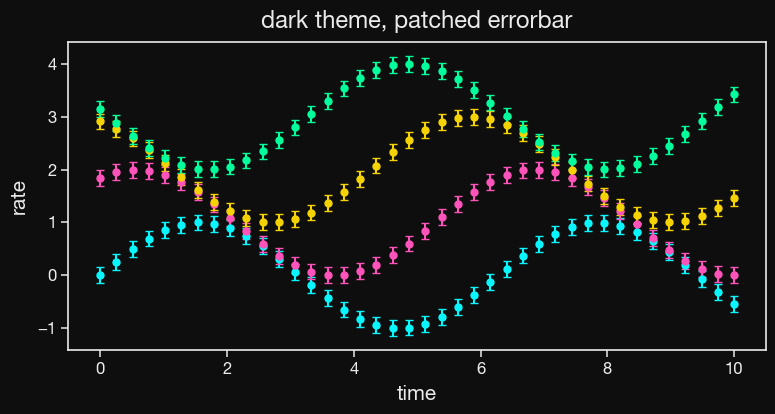

In [2]:
from pretty_plot import use

use('dark')

rng = np.random.default_rng(0)
x = np.linspace(0, 10, 40)

fig, ax = plt.subplots(figsize=(9, 4))
for k in range(4):
    y = np.sin(x + k) + k
    ax.errorbar(x, y, yerr=0.15)          # no fmt / capsize needed
ax.set_xlabel('time')
ax.set_ylabel('rate')
ax.set_title('dark theme, patched errorbar')
plt.show()

## 2. Flip to the light theme

Call `apply_plot_theme('light')` (or `use('light')`) and re-run the plot cells.
The `errorbar` patch is idempotent, so re-running `use()` never stacks wrappers.

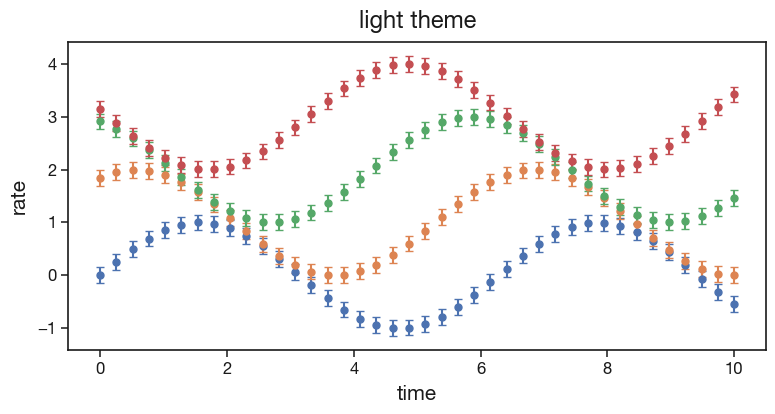

In [3]:
from pretty_plot import apply_plot_theme

apply_plot_theme('light')

fig, ax = plt.subplots(figsize=(9, 4))
for k in range(4):
    y = np.sin(x + k) + k
    ax.errorbar(x, y, yerr=0.15)
ax.set_xlabel('time')
ax.set_ylabel('rate')
ax.set_title('light theme')
plt.show()

## 2b. The playful themes — `tron` / `tron_orange` / `tron_red`, `cyber_punk`, `matrix`

Custom palettes for when a plot wants some personality. Each one sets its own
background, colour cycle and a faint colour-matched grid; `matrix` also switches
the whole figure to a monospace font. `tron_orange` and `tron_red` are the
orange- and red-dominant takes on the Tron look.

`cyber_punk` is the canonical name, but `'cyberpunk'` (and a few other
variants / misspellings) resolve to it too.

available themes: ('light', 'dark', 'tron', 'tron_orange', 'tron_red', 'cyber_punk', 'matrix')


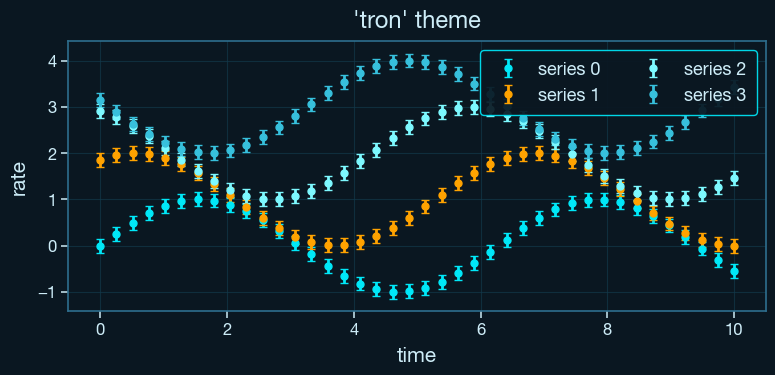

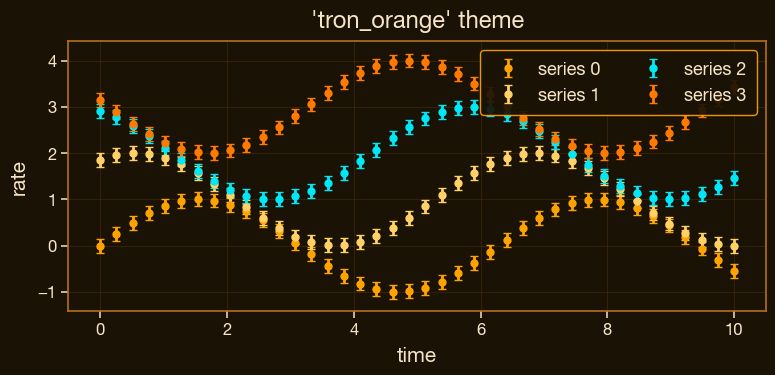

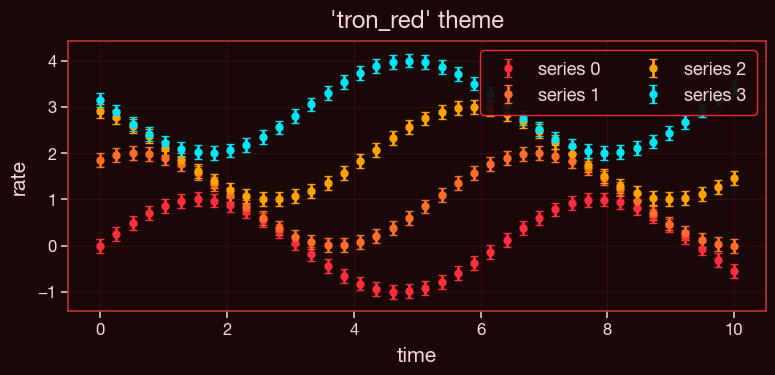

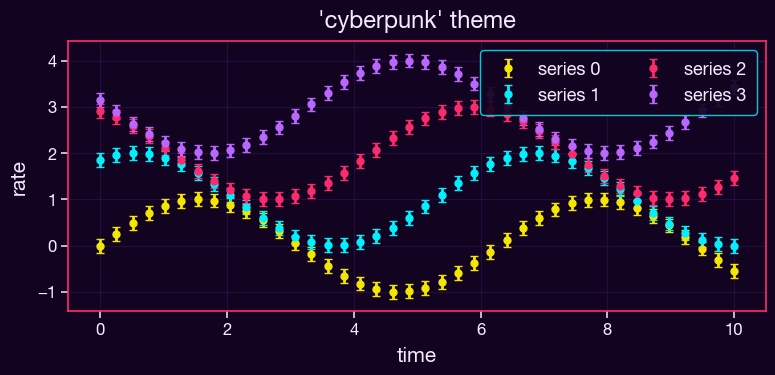

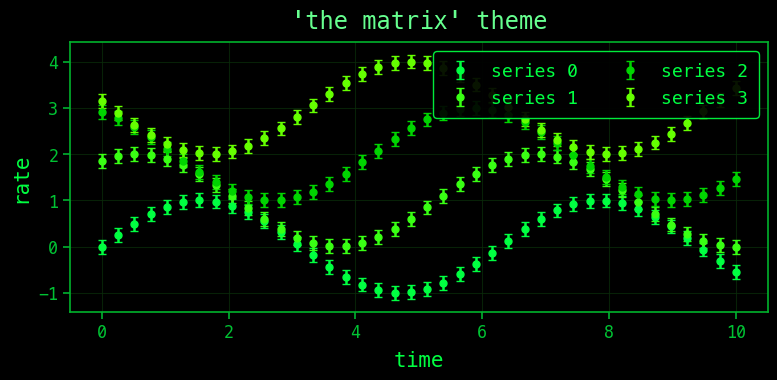

In [4]:
from pretty_plot import THEMES

print('available themes:', THEMES)

demo = ['tron', 'tron_orange', 'tron_red', 'cyberpunk', 'the matrix']  # loose spelling resolves

for name in demo:
    use(name)
    fig, ax = plt.subplots(figsize=(9, 3.5))
    for k in range(4):
        ax.errorbar(x, np.sin(x + k) + k, yerr=0.15, label=f'series {k}')
    ax.set_xlabel('time')
    ax.set_ylabel('rate')
    ax.set_title(f'{name!r} theme')
    ax.legend(loc='upper right', ncol=2)
    plt.show()

## 3. Theme without patching `errorbar`

If you want the colours/background but the normal `errorbar` default (a
connecting line), call `apply_plot_theme` on its own and skip `patch_errorbar`.

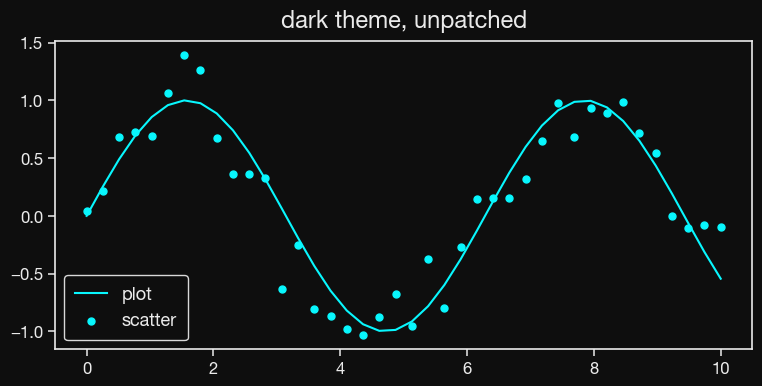

In [5]:
apply_plot_theme('dark')   # rcParams only, no monkeypatch

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x, np.sin(x), label='plot')
ax.scatter(x, np.sin(x) + 0.3 * rng.standard_normal(x.size), label='scatter')
ax.legend()
ax.set_title('dark theme, unpatched')
plt.show()

## 4. The colour cycles

`NEON`, `PASTEL`, `TRON`, `TRON_ORANGE`, `TRON_RED`, `CYBER_PUNK` and `MATRIX`
are plain lists of hex strings — use them directly when you need an explicit
colour.

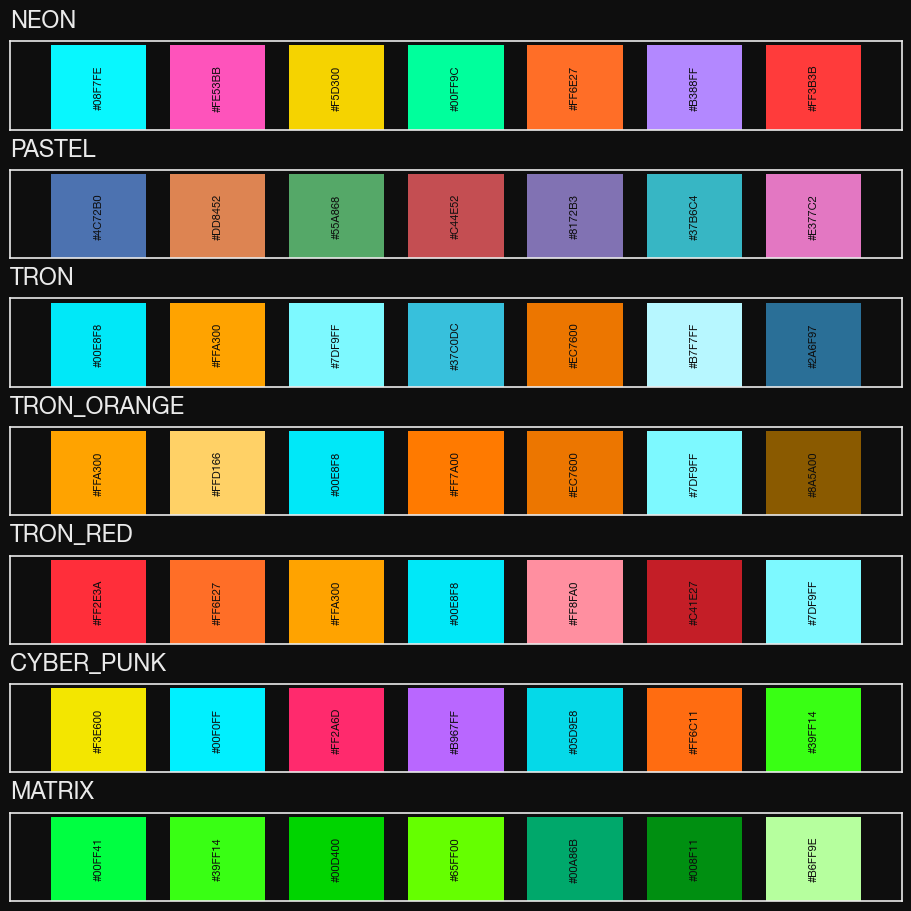

In [6]:
from pretty_plot import NEON, PASTEL, TRON, TRON_ORANGE, TRON_RED, CYBER_PUNK, MATRIX

cycles = {'NEON': NEON, 'PASTEL': PASTEL, 'TRON': TRON, 'TRON_ORANGE': TRON_ORANGE,
          'TRON_RED': TRON_RED, 'CYBER_PUNK': CYBER_PUNK, 'MATRIX': MATRIX}

apply_plot_theme('dark')
fig, axes = plt.subplots(len(cycles), 1, figsize=(9, 9), constrained_layout=True)
for ax, (name, cyc) in zip(axes, cycles.items()):
    for i, c in enumerate(cyc):
        ax.bar(i, 1, color=c)
        ax.text(i, 0.5, c, rotation=90, ha='center', va='center',
                color='#0E0E0E', fontsize=8)
    ax.set_title(name, loc='left')
    ax.set_yticks([])
    ax.set_xticks([])
plt.show()

## 5. Fonts, maths and the legend frame

Every theme bumps the fonts well above the matplotlib default, renders body text
in a bold family (monospace for `matrix`), draws `$...$` maths in Computer
Modern (the LaTeX look, with **no** TeX install needed), and gives the legend an
opaque framed box so it stays readable over busy plots.

- `font_scale` multiplies every size — pass `apply_plot_theme('dark', font_scale=1.3)`
  (or `use('dark', font_scale=1.3)`) for slides / print.
- `usetex=True` switches to a real LaTeX install; it needs `latex` + `dvipng` on
  PATH, otherwise every plot fails at draw time. Off by default.


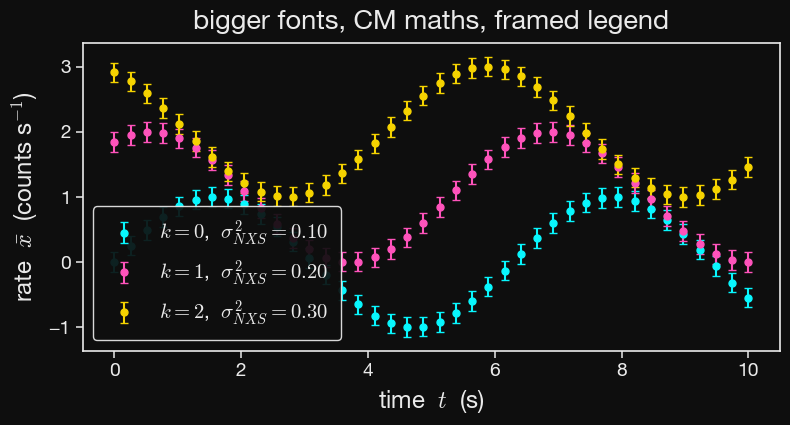

In [7]:
use('dark', font_scale=1.15)

fig, ax = plt.subplots(figsize=(9, 4))
for k in range(3):
    ax.errorbar(x, np.sin(x + k) + k, yerr=0.15,
                label=rf'$k = {k}$,  $\sigma^2_{{NXS}} = {0.1 * (k + 1):.2f}$')
ax.set_xlabel(r'time  $t$  (s)')
ax.set_ylabel(r'rate  $\bar{x}$  (counts s$^{-1}$)')
ax.set_title(r'bigger fonts, CM maths, framed legend')
ax.legend(loc='best')
plt.show()

## 5b. Modes — `regular`, `presenter`, `paper`

The theme picks the **colours**; the `mode` picks **sizes, weights and export
settings** for where the figure is going. Any theme works with any mode.

| mode | for | what changes |
|---|---|---|
| `regular` (default) | day-to-day notebooks | nothing — the look from the sections above |
| `presenter` | slides / talks | base font 20, bold, thick lines + spines, big markers, 16:9 figure (8 × 4.5 in), `savefig.dpi=200`, warns about oversized legends |
| `paper` | journal figures | one-column 3.5 × 2.6 in figure (text prints at 9–10 pt), Times/STIX serif, thin lines, inward ticks on all sides + minor ticks, frameless legend, saves **PDF** by default (PNG fallback 600 dpi), fonts embedded |

Figure sizes differ (3.5 in journal column vs ~8 in on a slide) but the
**text-to-figure ratio is the same** (~2.5 pt per inch of width), so both read at
the same relative size once inserted at their real size.

Aliases work too: `'slides'` / `'talk'` → `presenter`, `'journal'` /
`'publication'` → `paper`. Below, the **same plot code** is run in each mode —
note that no `figsize` is passed, so each mode's own figure size is used.

available modes: ('regular', 'presenter', 'paper')
dark / regular:  detected theme='dark', mode='regular', figsize=[6.4, 4.8], font.size=13.0


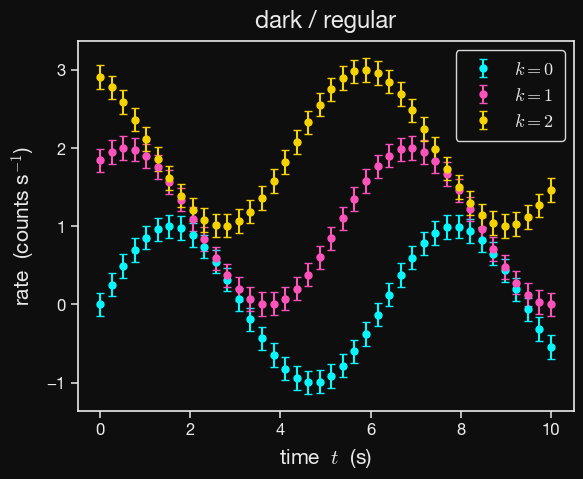

tron / presenter:  detected theme='tron', mode='presenter', figsize=[8.0, 4.5], font.size=20.0


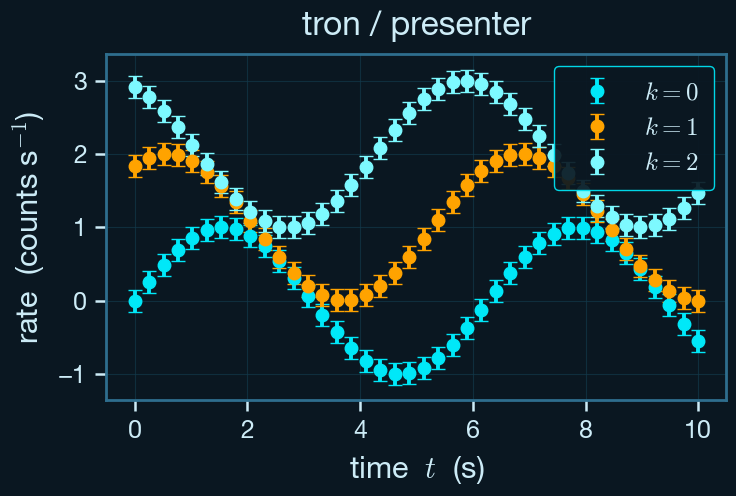

light / paper:  detected theme='light', mode='paper', figsize=[3.5, 2.6], font.size=10.0


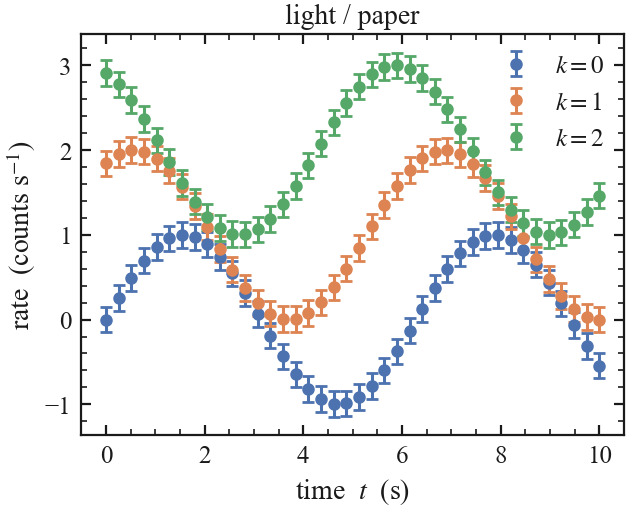

In [8]:
from pretty_plot import MODES, current_config

print('available modes:', MODES)

def demo_plot(title):
    fig, ax = plt.subplots()                 # no figsize: the mode decides
    for k in range(3):
        ax.errorbar(x, np.sin(x + k) + k, yerr=0.15, label=rf'$k = {k}$')
    ax.set_xlabel(r'time  $t$  (s)')
    ax.set_ylabel(r'rate  (counts s$^{-1}$)')
    ax.set_title(title)
    ax.legend(loc='upper right')
    plt.show()

for theme, mode in [('dark', 'regular'), ('tron', 'presenter'), ('light', 'paper')]:
    use(theme, mode=mode)
    cfg = current_config()
    print(f"{theme} / {mode}:  detected theme={cfg['theme']!r}, mode={cfg['mode']!r}, "
          f"figsize={list(plt.rcParams['figure.figsize'])}, font.size={plt.rcParams['font.size']}")
    demo_plot(f'{theme} / {mode}')

### Paper figures in practice — sharp and readable in LaTeX

**Make the figure at the width it is printed at; don't make it small and enlarge
it in LaTeX.** Enlarging a PNG makes it blurry; enlarging any figure makes the
fonts inconsistent with the text.

- `width=` sets the figure width (inches, or `'column'` = 3.5 in, `'page'` =
  7.1 in) and keeps the fonts at 9–10 pt, e.g. `use('light', mode='paper', width='page')`.
  For a thesis / single-column document use its `\textwidth` in inches
  (`\the\textwidth` in the `.tex` gives pt; ÷ 72.27).
- `fig.savefig('name')` with no extension writes a **PDF** — vector, never
  blurry. Include it at natural size: `\includegraphics{name.pdf}` (no `width=`).
- Pair `paper` with the `light` theme — journals want a white background.
- For a multi-panel full-width figure you can still pass `figsize=` directly,
  as below.

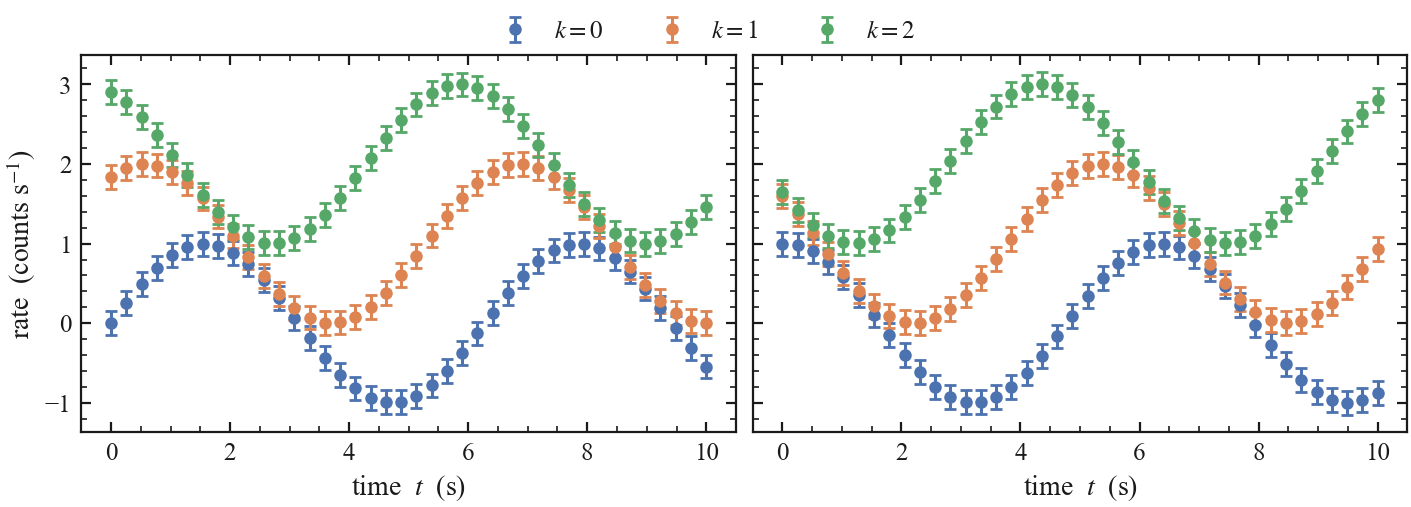

mode now: regular


In [9]:
import pretty_plot as pp

use('light', mode='paper')

fig, axes = plt.subplots(1, 2, figsize=(7.1, 2.6), sharey=True)   # double-column width
for ax, shift in zip(axes, (0, 1.5)):
    for k in range(3):
        ax.errorbar(x, np.sin(x + k + shift) + k, yerr=0.15, label=rf'$k = {k}$')
    ax.set_xlabel(r'time  $t$  (s)')
axes[0].set_ylabel(r'rate  (counts s$^{-1}$)')
pp.legend(where='top')   # one shared legend above both panels (see §5c)
# fig.savefig('lightcurves')   # -> lightcurves.pdf: vector, fonts embedded, tight bbox
plt.show()

use('dark')   # back to the day-to-day look (resets the paper settings)
print('mode now:', current_config()['mode'])

## 5c. Legends outside the plot

`pp.legend(where=...)` works in every mode. `where` is `'<side> [<align>]'`:

- side: `right`, `left`, `top`, `bottom` (`above` / `below` also work)
- align: `top` / `middle` / `bottom` on the left/right sides, `left` / `middle` / `right` on top/bottom (default `middle`)
- `where='inside'` (default) is a normal `ax.legend()`

Outside legends are figure legends: they gather the entries of **every** panel
(each label once) and the layout makes room automatically.

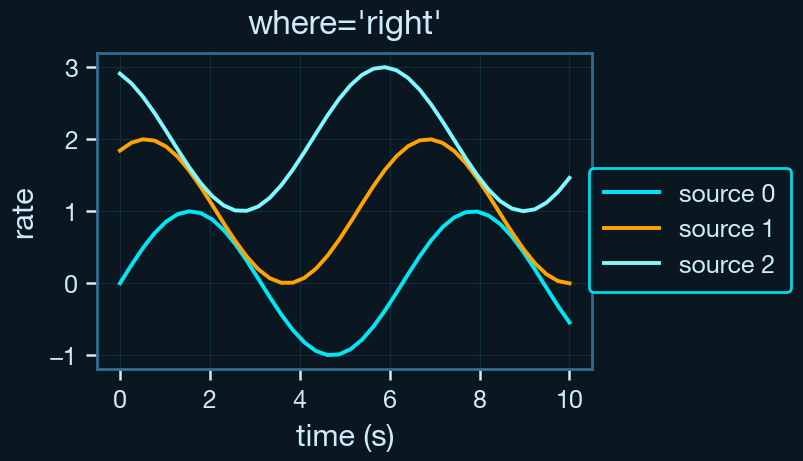

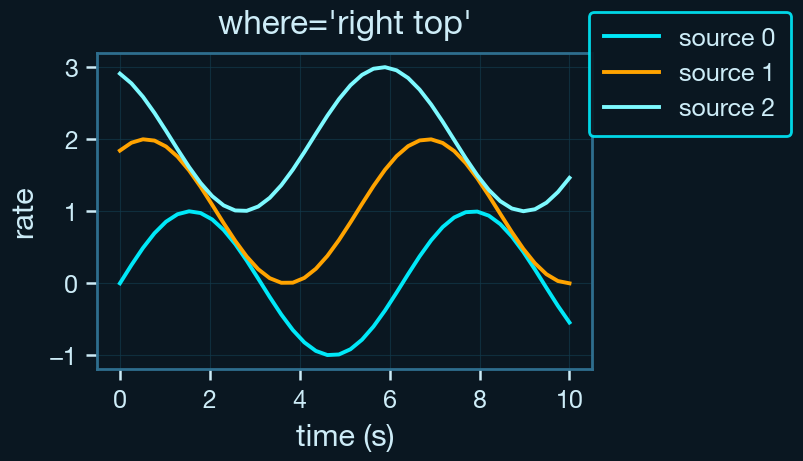

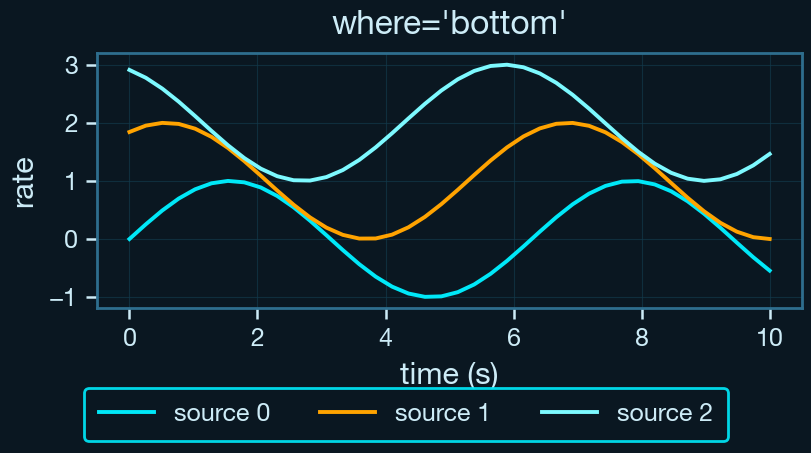

In [10]:
pp.use('tron', mode='presenter')

for where in ['right', 'right top', 'bottom']:
    fig, ax = plt.subplots()
    for k in range(3):
        ax.plot(x, np.sin(x + k) + k, label=f'source {k}')
    ax.set_xlabel('time (s)')
    ax.set_ylabel('rate')
    ax.set_title(f"where='{where}'")
    pp.legend(where=where)
    plt.show()

### Every mode, with or without a box: `frame`

`where=` works the same in `regular`, `presenter` and `paper`. `frame=True`
draws a line around the legend box (inside or outside), `frame=False` removes
it, and leaving it out gives the mode default (boxed in `regular` /
`presenter`, no box in `paper`). The line is as thick as the plot border
unless you pass `frame_width=`, and `edgecolor=` changes its colour.

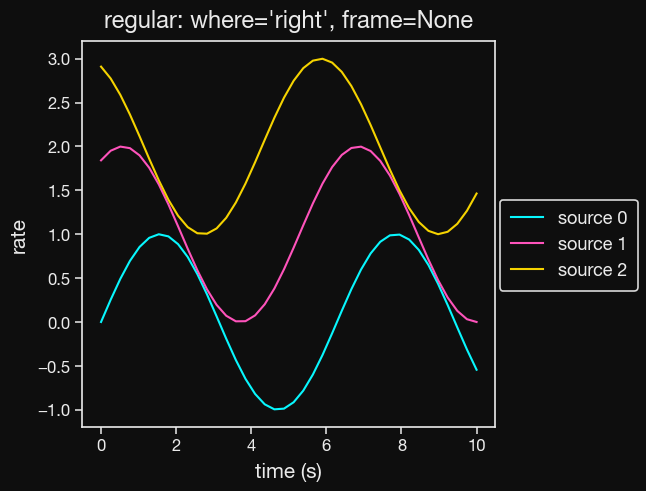

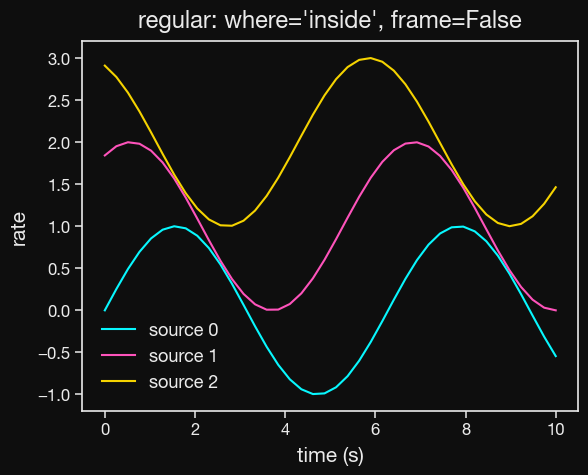

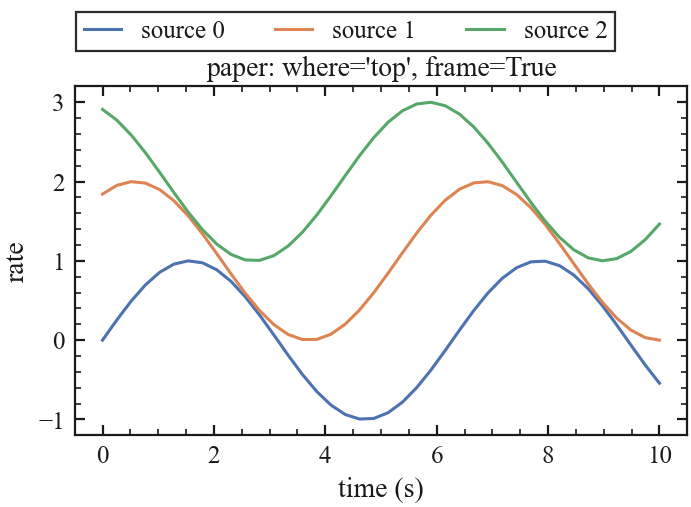

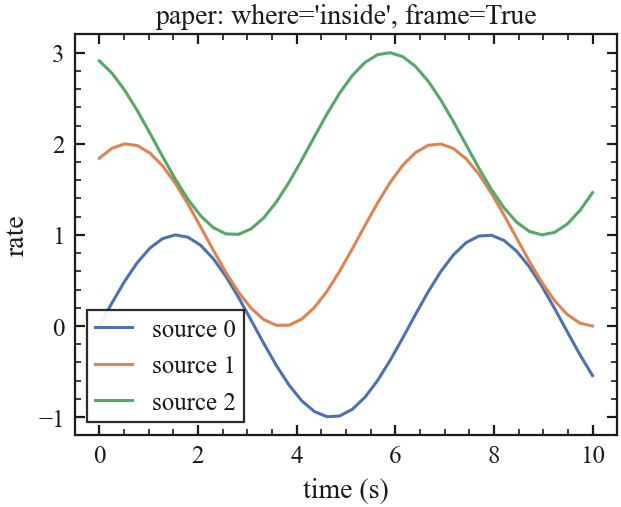

In [11]:
for theme, mode, where, frame in [('dark', 'regular', 'right', None),
                                  ('dark', 'regular', 'inside', False),
                                  ('light', 'paper', 'top', True),
                                  ('light', 'paper', 'inside', True)]:
    pp.use(theme, mode=mode)
    fig, ax = plt.subplots()
    for k in range(3):
        ax.plot(x, np.sin(x + k) + k, label=f'source {k}')
    ax.set_xlabel('time (s)')
    ax.set_ylabel('rate')
    ax.set_title(f"{mode}: where='{where}', frame={frame}")
    pp.legend(where=where, frame=frame)
    plt.show()

### Line width of the legend box: `frame_width`

`frame_width=` sets the thickness of the box line, in points. By default it
matches the plot border (`axes.linewidth`). Giving a width turns the box on by
itself, so it also works in `paper` mode, where legends have no box by default.
`frame_width=0` removes the box. Combine it with `edgecolor=` for the colour.
It works inside and outside the plot.

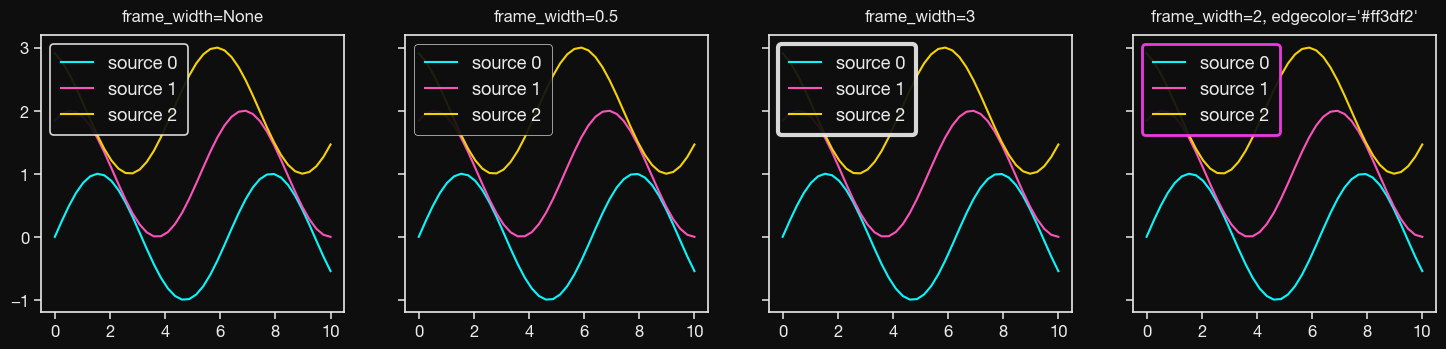

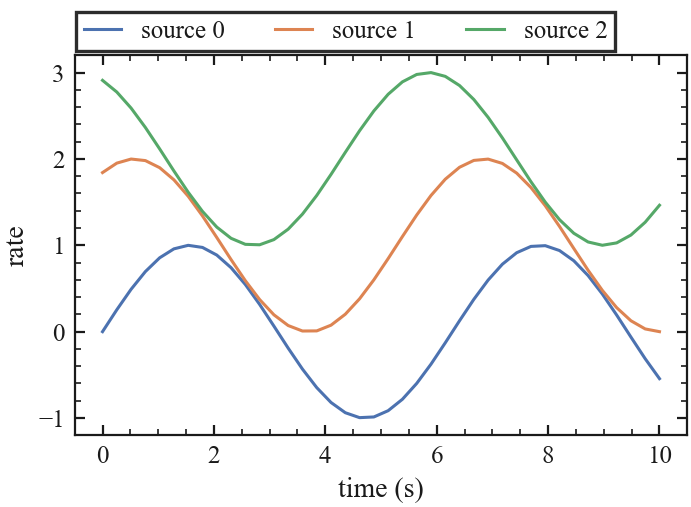

In [12]:
pp.use('dark')

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, (where, fw, extra) in zip(axes, [('inside', None, {}),
                                         ('inside', 0.5, {}),
                                         ('inside', 3, {}),
                                         ('inside', 2, {'edgecolor': '#ff3df2'})]):
    for k in range(3):
        ax.plot(x, np.sin(x + k) + k, label=f'source {k}')
    pp.legend(ax=ax, frame_width=fw, loc='upper left', **extra)
    ax.set_title(f'frame_width={fw}' + (f", edgecolor='{extra['edgecolor']}'" if extra else ''),
                 fontsize=12)
plt.show()

# paper mode: no box by default, frame_width alone turns it on (outside legend)
pp.use('light', mode='paper')
fig, ax = plt.subplots()
for k in range(3):
    ax.plot(x, np.sin(x + k) + k, label=f'source {k}')
ax.set_xlabel('time (s)')
ax.set_ylabel('rate')
pp.legend(where='top', frame_width=1.2)
plt.show()

### Plot–legend distance: `pad`

`pad` is in points (1 pt = 1/72 in). For an outside legend it is **extra** gap
on top of the default ~4–5 pt, measured from the plot *including* its tick and
axis labels; negative values pull the legend closer. For an inside legend it is
the gap to the axes edge.

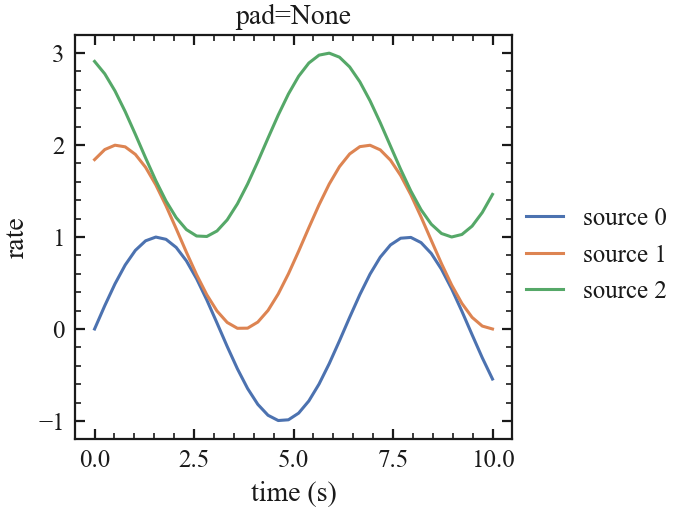

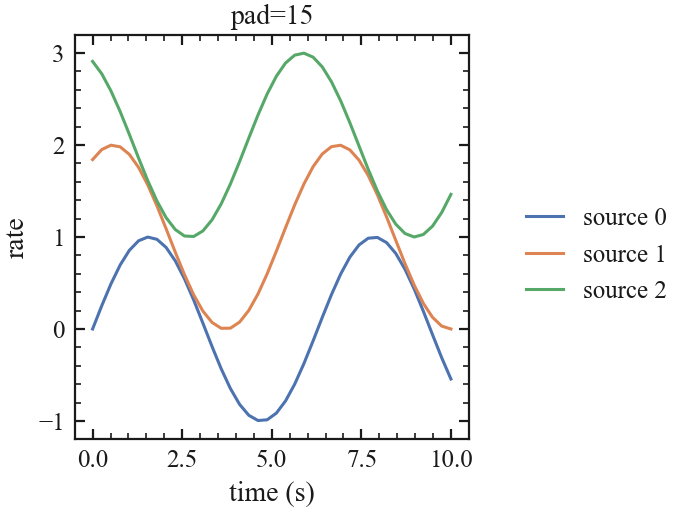

/Users/nvasilas/Analysis/Pretty_plot/pretty_plot/legend.py:288: SquashedPlotWarning: outside legend squashes the plot: the plot gets only 47% of the figure width (warning below 50%). Try a smaller pad (now 40 pt), where='top' / 'bottom', shorter labels, a larger figure width (now 3.5 in).
  _check_squash(self)


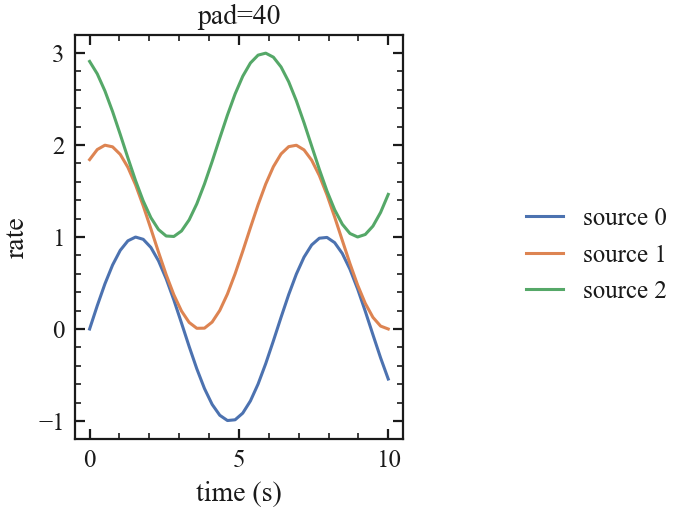

In [13]:
pp.use('light', mode='paper')

for pad in (None, 15, 40):
    fig, ax = plt.subplots()
    for k in range(3):
        ax.plot(x, np.sin(x + k) + k, label=f'source {k}')
    ax.set_xlabel('time (s)')
    ax.set_ylabel('rate')
    ax.set_title(f'pad={pad}')
    pp.legend(where='right', pad=pad)
    plt.show()

The legend's space comes **out of the figure**, so the plot shrinks to make
room. If an outside legend plus its `pad` leaves the plot **less than half** the
figure width (side legend) or height (top / bottom legend), you get a
`pp.SquashedPlotWarning` with suggestions. This works in every mode.

/Users/nvasilas/Analysis/Pretty_plot/pretty_plot/legend.py:288: SquashedPlotWarning: outside legend squashes the plot: the plot gets only 39% of the figure width (warning below 50%). Try a smaller pad (now 60 pt), where='top' / 'bottom', shorter labels, a larger figure width (now 3.5 in).
  _check_squash(self)


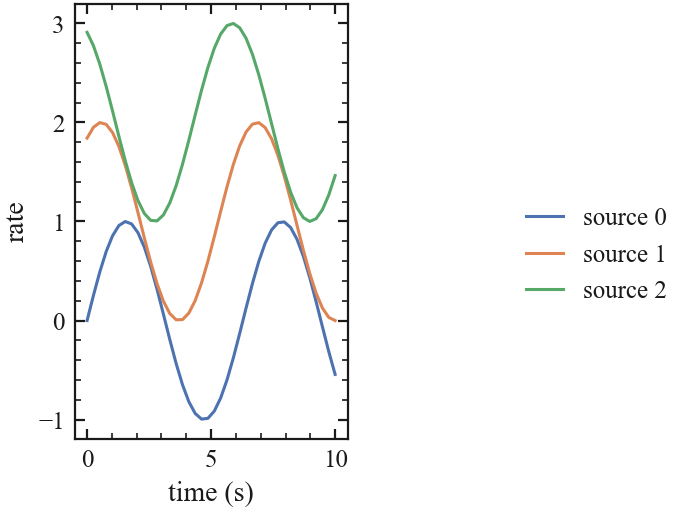

In [14]:
pp.use('light', mode='paper')

fig, ax = plt.subplots()
for k in range(3):
    ax.plot(x, np.sin(x + k) + k, label=f'source {k}')
ax.set_xlabel('time (s)')
ax.set_ylabel('rate')
pp.legend(where='right', pad=60)   # too much pad for a 3.5 in figure -> SquashedPlotWarning
plt.show()

### Oversized-legend warning (presenter mode)

On a slide a big legend eats the plot and can't be read from the back. In
`presenter` mode, a legend covering more than **25%** of its axes, or with more
than **6** entries, raises a `pp.LegendSizeWarning` when the figure is drawn.
The fix is usually fewer entries, `ncols=2`, or moving it outside.

Silence it with
`warnings.filterwarnings('ignore', category=pp.LegendSizeWarning)`.

/Users/nvasilas/Analysis/Pretty_plot/pretty_plot/legend.py:287: LegendSizeWarning: legend covers 32% of the axes (limit 25%) and has 9 entries (limit 6) -- hard to read on a slide. Try fewer entries, ncols=2, a shorter title, or pretty_plot.legend(where='right').
  _check_size(self, renderer)


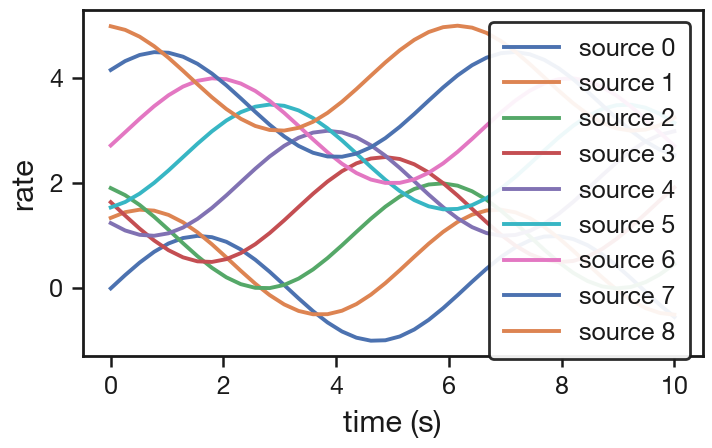

In [15]:
pp.use('light', mode='presenter')   # the check only runs in presenter mode

fig, ax = plt.subplots()
for k in range(9):
    ax.plot(x, np.sin(x + k) + 0.5 * k, label=f'source {k}')
ax.set_xlabel('time (s)')
ax.set_ylabel('rate')
pp.legend()          # 9 entries inside the axes -> LegendSizeWarning
plt.show()

use('dark')          # back to the day-to-day look

## 5d. Glow

`pp.glow()` makes the data glow, neon style. It is meant for the dark themes
(`dark`, `tron*`, `cyber_punk`, `matrix`). Each line, marker, error bar and
scatter gets a stack of wide, faint strokes in its own colour underneath it.
These are path effects, not a blur, so PDFs stay vector. Grid, spines and
text are left alone. **Legend entries glow like the artists they stand for**,
including the whole errorbar symbol (marker, whisker and caps), whether the
legend is made before or after `pp.glow()`. Error bars glow at the same
strength as the data. Pass `errorbars=0.5` for a softer glow, or `0` for none.

Call it **after plotting**. With no argument it lights up everything in the
current figure.

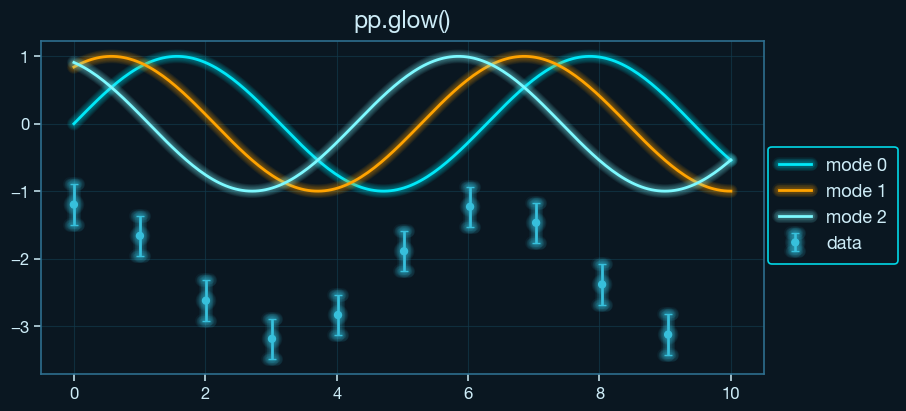

In [16]:
pp.use('tron')

t = np.linspace(0, 10, 200)
fig, ax = plt.subplots(figsize=(9, 4))
for k in range(3):
    ax.plot(t, np.sin(t + k), label=f'mode {k}')
ax.errorbar(t[::20], np.cos(t[::20]) - 2.2, yerr=0.3, label='data')
pp.legend(where='right')
pp.glow()                 # everything; strength=2 for stronger, size= for wider
ax.set_title('pp.glow()')
plt.show()

### Error bars: control the points and the bars separately

In an errorbar plot, two options set the glow of each part, as multipliers of
`strength`:

- `markers=` sets the **data points** (the markers, and the line through them
  if there is one).
- `errorbars=` sets the **whiskers and caps**.

| call | result |
|---|---|
| `pp.glow(ax)` | everything glows (both `1`) |
| `pp.glow(ax, errorbars=0)` | only the points glow |
| `pp.glow(ax, markers=0)` | only the bars glow |
| `pp.glow(ax, markers=2.5, errorbars=0.5)` | bright points on softly glowing bars |
| `pp.glow(ax, color='#ff3df2', errorbars=0)` | own glow colour, here on the points only |

`color=` sets the glow colour for everything in the call. Without it, each
part glows in its own colour. The legend entry always follows these choices.
For automatic glow, pass the same options as a dict, e.g.
`pp.use('tron', glow={'markers': 2, 'errorbars': 0.5})`.


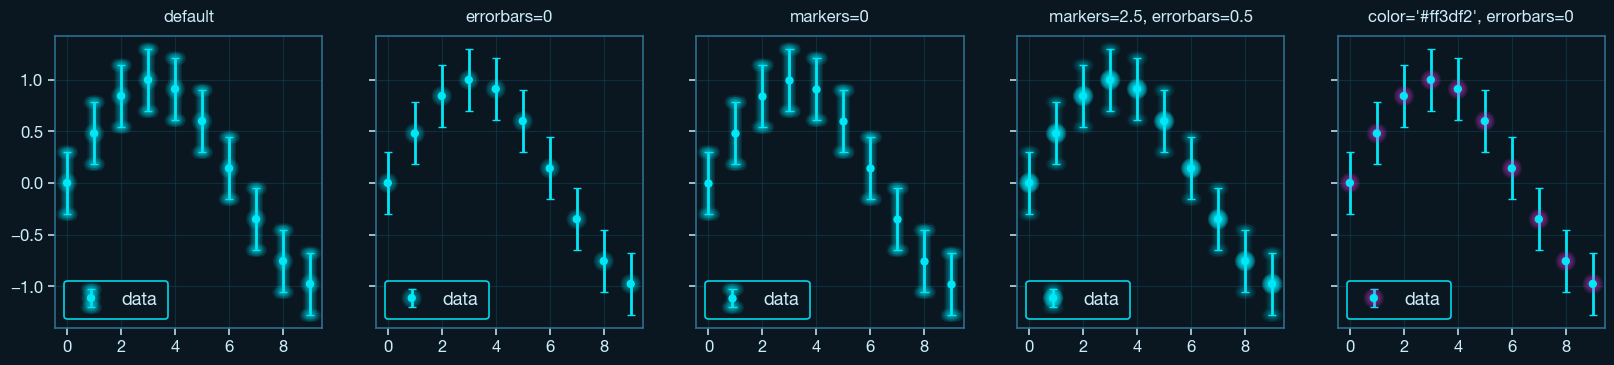

In [17]:
pp.use('tron')
xe = np.arange(10)
options = [{},
           {'errorbars': 0},
           {'markers': 0},
           {'markers': 2.5, 'errorbars': 0.5},
           {'color': '#ff3df2', 'errorbars': 0}]
fig, axes = plt.subplots(1, len(options), figsize=(20, 3.8), sharey=True)
for ax, kw in zip(axes, options):
    ax.errorbar(xe, np.sin(xe / 2), yerr=0.3, label='data')
    pp.legend(ax=ax, loc='lower left')
    pp.glow(ax, **kw)
    ax.set_title(', '.join(f'{k}={v!r}' for k, v in kw.items()) or 'default', fontsize=12)
plt.show()


### Glow only some components

The first argument can be anything you plotted, so you choose what lights up:

| call | glows |
|---|---|
| `pp.glow(line)` | one line (`line, = ax.plot(...)`) |
| `pp.glow(sc)` | one scatter (`sc = ax.scatter(...)`) |
| `pp.glow([line, eb])` | a chosen set: lines, scatters, `errorbar` / `bar` containers |
| `pp.glow(sc, points=mask)` | only **some points** of a scatter (bool mask, indices or slice) |
| `pp.glow(line, points=slice(i, j))` | only a **segment** of a line |
| `pp.glow(ax)` / `pp.glow(fig)` | one axes / a whole figure |

`color=` sets your own glow colour. A colormapped scatter needs it, because it
has no single colour.

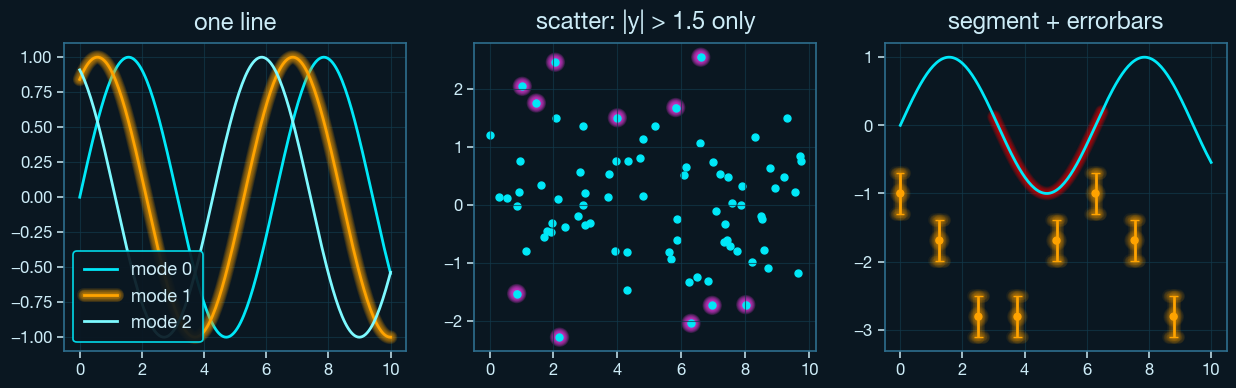

In [18]:
pp.use('tron')
rng = np.random.default_rng(3)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# one line out of three
ax = axes[0]
lines = [ax.plot(t, np.sin(t + k), label=f'mode {k}')[0] for k in range(3)]
pp.glow(lines[1], strength=2)
pp.legend(ax=ax, loc='lower left')
ax.set_title('one line')

# only the outliers of a scatter, in a colour of your choice
ax = axes[1]
xs = rng.uniform(0, 10, 80)
ys = rng.normal(size=80)
sc = ax.scatter(xs, ys)
pp.glow(sc, points=np.abs(ys) > 1.5, color='#ff3df2', strength=2.5)
ax.set_title('scatter: |y| > 1.5 only')

# a segment of a line + one errorbar set
ax = axes[2]
seg, = ax.plot(t, np.sin(t))
eb = ax.errorbar(t[::25], np.cos(t[::25]) - 2, yerr=0.3)
# pp.glow(seg, points=(t > 3) & (t < 6.5), strength=2) # this plot the glow in the same color as the line
pp.glow(seg, points=(t > 3) & (t < 6.5), strength=2, color = 'red') # plot the glow effect in a different color
pp.glow(eb)                # data points, whiskers and caps
ax.set_title('segment + errorbars')
plt.show()

### Automatic glow, with exceptions

`pp.use(theme, glow=True)` makes every plot glow. You can also pass a number
for the strength, or a dict such as `{'strength': 2, 'errorbars': 0}`. Single
artists can still be adjusted afterwards: `strength=0` switches one off, and
a higher strength makes one brighter.

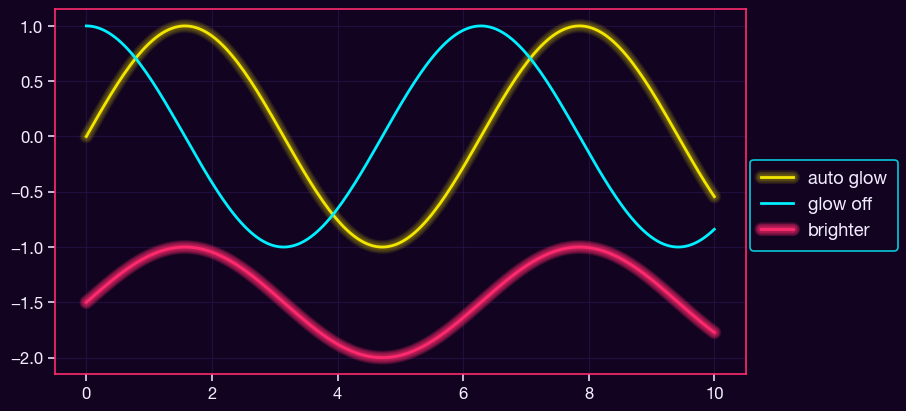

In [19]:
pp.use('cyber_punk', glow=True)

fig, ax = plt.subplots(figsize=(9, 4))
a, = ax.plot(t, np.sin(t), label='auto glow')
b, = ax.plot(t, np.cos(t), label='glow off')
c, = ax.plot(t, np.sin(t) * 0.5 - 1.5, label='brighter')
pp.glow(b, strength=0)
pp.glow(c, strength=2.5)
pp.legend(where='right')
plt.show()

In `paper` mode glow is skipped with a `GlowWarning`, because journals and print
don't want it. Pass `force=True` to apply it anyway. On a light theme it is
applied but warned about, since it looks blurry there rather than neon.

In [20]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    pp.use('light', mode='paper')
    fig, ax = plt.subplots()
    ax.plot(t, np.sin(t))
    pp.glow()
    plt.close(fig)
for w in caught:
    print(f'{w.category.__name__}: {w.message}')

pp.use('dark')   # back to the default for the rest of the notebook

## 6. Extending the package

Because it is installed editable, add a module under `pretty_plot/` and
re-export it from `pretty_plot/__init__.py`:

```python
# pretty_plot/panels.py
import matplotlib.pyplot as plt

def lc_panel(ax, t, rate, err, **kw):
    ax.errorbar(t, rate, yerr=err, **kw)
    ax.set_xlabel('time (days)')
    ax.set_ylabel('rate (counts/s)')
    return ax
```

```python
# add to pretty_plot/__init__.py
from .panels import lc_panel
```

Editing an existing module takes effect on the next kernel restart (or with
`%load_ext autoreload` / `%autoreload 2`). A brand-new module needs a kernel
restart to be importable.

## 7. Reference: everything you can call

Everything below is available as `pp.<name>` after `import pretty_plot as pp`.
For the full docstring of any of them, run `help(pp.glow)`, or `pp.glow?` in
Jupyter.

### Functions

| call | what it does |
|---|---|
| `pp.use(theme='dark', patch_errorbars=True, font_scale=1.0, usetex=False, font=None, mode='regular', width=None, glow=False)` | **the one-liner**: applies a theme and mode and patches `errorbar` (§1, §5b) |
| `pp.apply_plot_theme(theme='dark', font_scale=1.0, usetex=False, font=None, mode='regular', width=None, glow=False)` | same as `use`, without the `errorbar` patch (§2, §3) |
| `pp.patch_errorbar(fmt='o')` | makes every `ax.errorbar` default to `fmt` (points, no line); idempotent |
| `pp.theme_config(theme='dark', font_scale=1.0, usetex=False, font=None, mode='regular', width=None)` | returns the rcParams a theme *would* set, as a dict, without applying them |
| `pp.current_config(full=False)` | rcParams in effect now, plus the detected `theme`, `mode` and `errorbar.patched` |
| `pp.legend(where='inside', ax=None, fig=None, pad=None, frame=None, frame_width=None, **kwargs)` | legend inside, or outside on any side, with optional box (§5c) |
| `pp.glow(target=None, strength=1.0, size=None, layers=8, errorbars=1.0, markers=1.0, color=None, points=None, force=False)` | neon glow on a figure, an axes, chosen artists or some points (§5d) |

### Arguments of `use` / `apply_plot_theme` / `theme_config`

| argument | values |
|---|---|
| `theme` | `'light'`, `'dark'`, `'tron'`, `'tron_orange'`, `'tron_red'`, `'cyber_punk'`, `'matrix'`; case-insensitive, aliases such as `'cyberpunk'`, `'the matrix'`, `'red tron'`, `'tron_blue'` |
| `mode` | `'regular'` (alias `'default'`, `'notebook'`, …), `'presenter'` (`'slides'`, `'talk'`, …), `'paper'` (`'journal'`, `'print'`, …) |
| `font_scale` | multiplies every font size of the mode, e.g. `1.2` |
| `font` | font family name or list, replacing the default stack (`DEFAULT_SANS` / `DEFAULT_SERIF` / `DEFAULT_MONO`) |
| `usetex` | `True` = real LaTeX (needs `latex` + `dvipng`); default mathtext already looks like LaTeX |
| `width` | figure width in inches, or `'column'` / `'single'` (3.5 in), `'page'` / `'double'` / `'full'` / `'textwidth'` (7.1 in); keeps the aspect ratio |
| `glow` | `True`, a strength number, or a dict of `glow` options (`strength`, `size`, `layers`, `errorbars`, `markers`); not in `theme_config` |
| `patch_errorbars` | `use` only: `False` skips the `errorbar` patch |

### Arguments of `legend`

| argument | values |
|---|---|
| `where` | `'inside'`, or `'<side> [<align>]'`: side `right` / `left` / `top` / `bottom` (`above` / `below`), align `top` / `middle` / `bottom` or `left` / `middle` / `right` |
| `pad` | extra plot–legend distance in points (outside), or legend–axes-edge gap (inside) |
| `frame` | `True` box, `False` no box, `None` mode default |
| `frame_width` | box line width in points (turns the box on; `0` = no box) |
| `ax`, `fig` | which axes / figure (default: current) |
| `**kwargs` | anything `ax.legend` / `fig.legend` takes: `ncols`, `title`, `edgecolor`, `loc`, `fontsize`, … |

### Arguments of `glow`

| argument | values |
|---|---|
| `target` | `None` (current figure), an `Axes`, a `Figure`, a line, a scatter, an `errorbar` / `bar` container, or a list of these |
| `strength` | halo brightness: `1` soft, `2` strong, `0` off |
| `size` | halo reach in points (default `4 × lines.linewidth`) |
| `layers` | number of halo strokes (smoothness) |
| `errorbars` | multiplier for whiskers and caps (`0` = only the points glow) |
| `markers` | multiplier for errorbar data points (`0` = only the bars glow) |
| `color` | one glow colour for everything in the call |
| `points` | only these points of one line or scatter: mask, indices or slice |
| `force` | `True` = apply in `paper` mode too |

### Constants

| name | value |
|---|---|
| `pp.THEMES` | tuple of theme names |
| `pp.MODES` | `('regular', 'presenter', 'paper')` |
| `pp.DEFAULT_THEME`, `pp.DEFAULT_MODE` | `'dark'`, `'regular'` |
| `pp.DEFAULT_SANS`, `pp.DEFAULT_SERIF`, `pp.DEFAULT_MONO` | the default font stacks (tuples, first installed font wins) |
| `pp.NEON`, `pp.PASTEL`, `pp.TRON`, `pp.TRON_ORANGE`, `pp.TRON_RED`, `pp.CYBER_PUNK`, `pp.MATRIX` | colour cycles (lists of hex colours), e.g. `color=pp.NEON[2]` |
| `pp.__version__` | package version |

### Warning classes

All three are `UserWarning` subclasses, so you can filter them, e.g.
`warnings.filterwarnings('ignore', category=pp.GlowWarning)`.

| class | raised when |
|---|---|
| `pp.LegendSizeWarning` | `presenter` mode: a legend covers > 25% of its axes or has > 6 entries |
| `pp.SquashedPlotWarning` | an outside legend (plus `pad`) leaves the plot < 50% of the figure |
| `pp.GlowWarning` | glow skipped in `paper` mode, or used on a light background |

The cell below lists the same things straight from the installed package, so
it is always up to date:

In [21]:
import inspect

for name in pretty_plot.__all__:
    obj = getattr(pretty_plot, name)
    doc = (inspect.getdoc(obj) or '').split('\n')[0] if callable(obj) else ''
    if inspect.isclass(obj):
        print(f'class  {name}({obj.__mro__[1].__name__})\n         {doc}')
    elif callable(obj):
        print(f'def    {name}{inspect.signature(obj)}\n         {doc}')
    else:
        print(f'const  {name} = {obj!r}'[:110])

const  __version__ = '0.7.0'
const  DEFAULT_THEME = 'dark'
const  DEFAULT_SANS = ('Helvetica Neue', 'Helvetica', 'Arial', 'TeX Gyre Heros', 'DejaVu Sans')
const  DEFAULT_MONO = ('JetBrains Mono', 'Fira Code', 'Menlo', 'Consolas', 'DejaVu Sans Mono')
const  DEFAULT_SERIF = ('Times New Roman', 'Times', 'STIX Two Text', 'STIXGeneral', 'DejaVu Serif')
const  THEMES = ('light', 'dark', 'tron', 'tron_orange', 'tron_red', 'cyber_punk', 'matrix')
const  MODES = ('regular', 'presenter', 'paper')
const  DEFAULT_MODE = 'regular'
const  NEON = ['#08F7FE', '#FE53BB', '#F5D300', '#00FF9C', '#FF6E27', '#B388FF', '#FF3B3B']
const  PASTEL = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3', '#37B6C4', '#E377C2']
const  TRON = ['#00E8F8', '#FFA300', '#7DF9FF', '#37C0DC', '#EC7600', '#B7F7FF', '#2A6F97']
const  TRON_ORANGE = ['#FFA300', '#FFD166', '#00E8F8', '#FF7A00', '#EC7600', '#7DF9FF', '#8A5A00']
const  TRON_RED = ['#FF2E3A', '#FF6E27', '#FFA300', '#00E8F8', '#FF8FA0', '#C41E27', '#7DF9FF']
con